In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Admin\Desktop\projects\Data Science-1pm\Pandas\insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [6]:
sigma = df['bmi'].std()
mean = df['bmi'].mean()

In [7]:
n_sample = 100
sample_size = 30
samples_mean = []
for i in range(n_sample):
    samples_mean.append(df['bmi'].sample(sample_size).mean())

In [8]:
import seaborn as sns

<Axes: xlabel='bmi', ylabel='Density'>

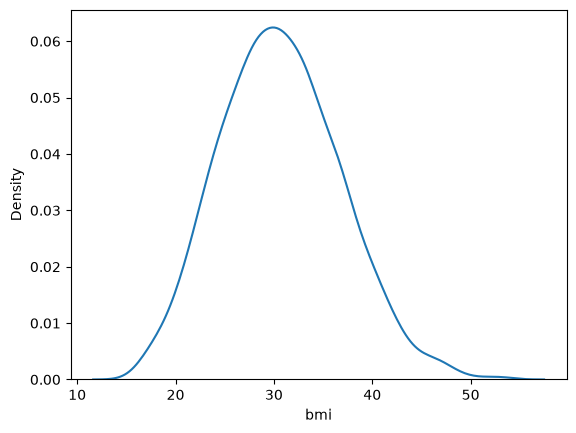

In [9]:
sns.kdeplot(df['bmi'])

<Axes: ylabel='Density'>

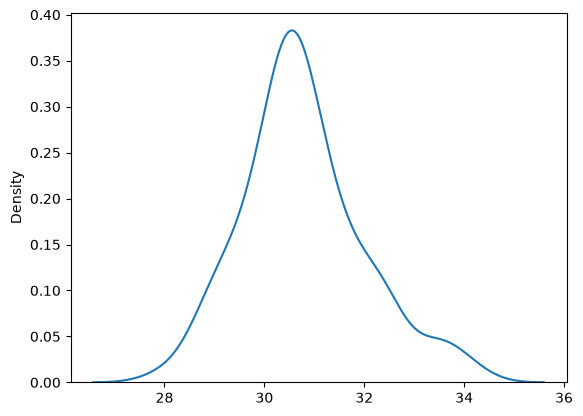

In [10]:
sns.kdeplot(samples_mean)

In [11]:
point_estimate = np.mean(np.array(samples_mean))

In [12]:
# confidence level is 90%
# alpha = 10%

lower_margin = point_estimate - (1.645 * sigma)/np.sqrt(sample_size)
upper_margin = point_estimate + (1.645 * sigma)/np.sqrt(sample_size)

In [13]:
print(f"Confidence interval having 90% of CL having my pop parameter = {mean} lies in ({lower_margin} - {upper_margin})")

Confidence interval having 90% of CL having my pop parameter = 30.66339686098655 lies in (28.944320531943863 - 32.60731280138946)


In [26]:
def confidence_interval(data, CL):
    mean = data.mean()
    sigma = data.std()
    n_sample = 200
    sample_size = 50
    samples_mean = []
    for i in range(n_sample):
        samples_mean.append(data.sample(sample_size).mean())

    plt.figure(figsize=(5, 5))
    plt.subplot(1,2, 1)
    sns.kdeplot(data)

    plt.subplot(1, 2, 2)
    sns.kdeplot(samples_mean)
    plt.tight_layout()
    plt.show()

    print()

    point_estimate = np.mean(np.array(samples_mean))
    lower_margin = np.round(point_estimate - (1.645 * sigma)/np.sqrt(sample_size), 3)
    upper_margin = np.round(point_estimate + (1.645 * sigma)/np.sqrt(sample_size), 3)
    print(f"Confidence interval having {CL} confidence level & my pop parameter = {np.round(mean, 3)} lies in ({lower_margin} - {upper_margin})")

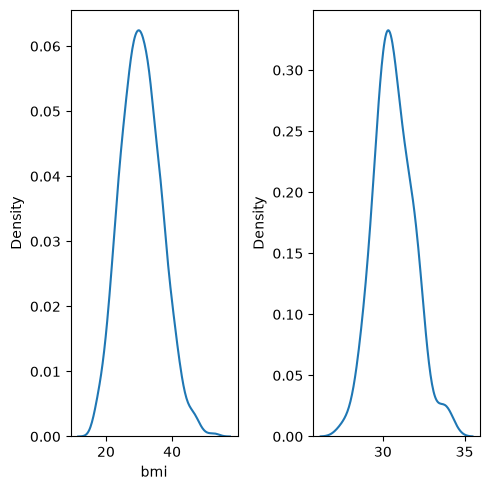


Confidence interval having 95 confidence level & my pop parameter = 30.663 lies in (28.473 - 32.837)


In [22]:
confidence_interval(df['bmi'], 95)

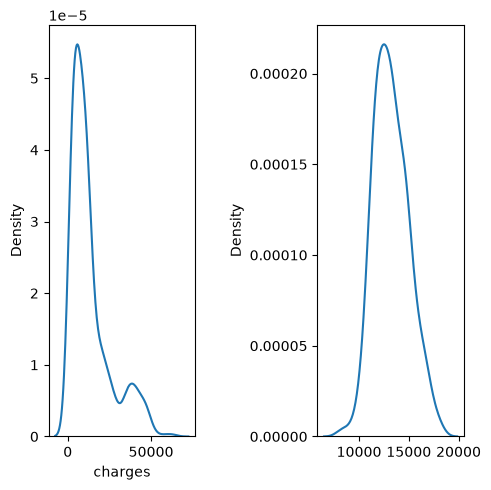


Confidence interval having 90 confidence level & my pop parameter = 13270.422 lies in (10410.614 - 16045.115)


In [27]:
confidence_interval(df['charges'], 90)